# Figure 4 | SNOWPACK simulations and observed snow depth

Publication revision of [the in-review notebook](inreview/figure4.ipynb).
The main figure uses the two lapse-rate forcing configurations with soil
enabled. The supplementary comparison retains all four original base runs.
Both figures retain the September–August display windows from the review
notebook. The WY subtitles identify the three winter seasons in each panel.

In [11]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd
import seaborn as sns
import xarray as xr

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'envs/rasterio.yml').is_file() and (p / 'figures').is_dir())
output_dir = root / 'figures/files'
model_root = Path('/home/cassie/python/models/run_snowpack/sites')
data_root = Path('/hdd/snow_hydrology')

# Display name, water-year range, mixed forcing file span, station file.
sites = {
    'ppsa': ('Powder Patch Meteorological Station (PPSA)', 2023, 2025, 'WY2020-WY2025',
             'ppsa2/pppsa_met_station_data_synoptic_2026-03-20'),
    'tram': ('Mount Roberts Tramway Meteorological Station (TRAM)', 2023, 2025, 'WY2023-WY2025',
             'tram/tram_met_station_data_synoptic_2026-03-20'),
    'heen': ('Heen Latinee SNOTEL (HEEN)', 2020, 2022, 'WY2020-WY2022',
             'snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc'),
}

styles = {
    'hrrrak': ('HRRR-AK Raw', 'tab:purple'),
    'hrrrak_lapserate': ('HRRR-AK Forcing', 'tab:blue'),
    'met_hrrrak': ('Met Mixed + Raw HRRR-AK Fill', 'tab:orange'),
    'met_hrrrak_lapserate': ('Met Mixed Forcing', 'tab:green'),
}
main_forcings = ('hrrrak_lapserate', 'met_hrrrak_lapserate')

In [12]:
def read_snow_depth(path):
    header = {}
    with path.open() as source:
        for line in source:
            if line.strip() == '[DATA]':
                break
            if '=' in line:
                key, value = line.split('=', 1)
                header[key.strip()] = value.strip()
        else:
            raise ValueError(f'Missing [DATA] section in {path}')
        fields = header['fields'].split()
        data = pd.read_csv(source, sep=r'\s+', names=fields,
                           usecols=['timestamp', 'HS_mod'], index_col='timestamp',
                           parse_dates=['timestamp'], na_values=float(header['nodata']))
    if data.empty or not data.index.is_unique or not data.index.is_monotonic_increasing:
        raise ValueError(f'Expected a nonempty, ordered snow depth series in {path}')
    # SMET's multiplier converts the stored value to meters. Plot centimeters.
    multiplier = float(header['units_multiplier'].split()[fields.index('HS_mod')])
    return data['HS_mod'] * multiplier * 100


def load_simulations(forcings, version):
    return {
        site: {
            forcing: read_snow_depth(
                model_root / site / 'output' /
                ('_wrong_elevation' if version == 'base' and site == 'heen' else '.') /
                f"{forcing}_{site}_{mixed_span if forcing.startswith('met_') else 'WY2020-WY2025'}_{version}.smet"
            )
            for forcing in forcings
        }
        for site, (_, _, _, mixed_span, _) in sites.items()
    }


observed = {}
for site, (_, _, _, _, filename) in sites.items():
    with xr.open_dataset(data_root / 'met_station' / filename) as ds:
        observed[site] = ds['hs'].to_series().sort_index()

pits = pd.read_csv(data_root / 'field_data/snow_pit_swe_measurements_WY2025.csv',
                   index_col=0, parse_dates=True)['snow_depth_cm'].sort_index()

In [13]:
def format_month_ticks(ax, *, labels=True):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 6, 10], bymonthday=1))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonthday=1))

    def label_date(value, _):
        date = mdates.num2date(value)
        month = {1: 'Jan', 6: 'June', 10: 'Oct'}[date.month]
        return f'1 {month}\n{date.year}'

    ax.xaxis.set_major_formatter(FuncFormatter(label_date))
    ax.tick_params(axis='x', which='major', bottom=True, labelbottom=labels,
                   length=5, width=0.8, color='#46515b', labelsize=9)
    ax.tick_params(axis='x', which='minor', bottom=True, labelbottom=False,
                   length=3, width=0.7, color='#46515b')


def draw_figure(simulations, stem, *, ymax, supplementary=False):
    with sns.axes_style('darkgrid'), mpl.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42}):
        fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharey=True)
        axes[1].sharex(axes[0])
        fig.subplots_adjust(left=0.09, right=0.98, top=0.83 if supplementary else 0.86,
                            bottom=0.085, hspace=0.45)

        for index, (ax, (site, (name, first, last, _, _))) in enumerate(zip(axes, sites.items())):
            start, end = pd.Timestamp(f'{first - 1}-09-01'), pd.Timestamp(f'{last}-08-30')
            for forcing, series in simulations[site].items():
                label, color = styles[forcing]
                trace = series.loc[start:end]
                ax.plot(trace.index, trace, color=color, linewidth=2, label=label)

            station = observed[site].loc[start:end]
            ax.plot(station.index, station, color='black', linestyle='--', linewidth=1.7,
                    label='Met Station Observations')
            if site == 'ppsa':
                ax.plot(pits.index, pits, linestyle='none', marker='o', color='black',
                        markersize=6, markeredgecolor='white', markeredgewidth=1,
                        label='Snow Pit Observations', zorder=10)

            ax.set(xlim=(start, end), ylim=(-10, ymax), ylabel='snow depth (cm)')
            ax.set_title(name, loc='left', fontsize=12, fontweight='normal', pad=16)
            ax.text(0, 1.025, f'WY {first}–{last}', transform=ax.transAxes,
                    ha='left', va='bottom', fontsize=9, color='#45515a')
            ax.text(0.009, 0.96, f'{chr(65 + index)})', transform=ax.transAxes,
                    ha='left', va='top', fontsize=10, color='dimgrey')
            ax.tick_params(axis='y', labelsize=9)
            ax.grid(alpha=0.55)
            format_month_ticks(ax, labels=index != 0)

        heading = 'SNOWPACK simulations and observed snow depth'
        if supplementary:
            heading += ' | Supplementary comparison'
        fig.text(0.09, 0.975, heading, ha='left', va='top', fontsize=16, weight='bold')
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='upper left', bbox_to_anchor=(0.09, 0.938),
                   ncols=3 if supplementary else 4, fontsize=9, framealpha=1,
                   facecolor=axes[0].get_facecolor(), edgecolor='#d1d3dc', borderaxespad=0)

        output_dir.mkdir(parents=True, exist_ok=True)
        for extension in ('png', 'pdf'):
            fig.savefig(output_dir / f'{stem}.{extension}', dpi=300, facecolor='white')
        return fig

## Main figure | Soil simulations

Blue and green show the lapse-rate HRRR-AK run and the mixed station-forcing
run with lapse-rate HRRR-AK fill, respectively. Both use the `_soil` outputs.

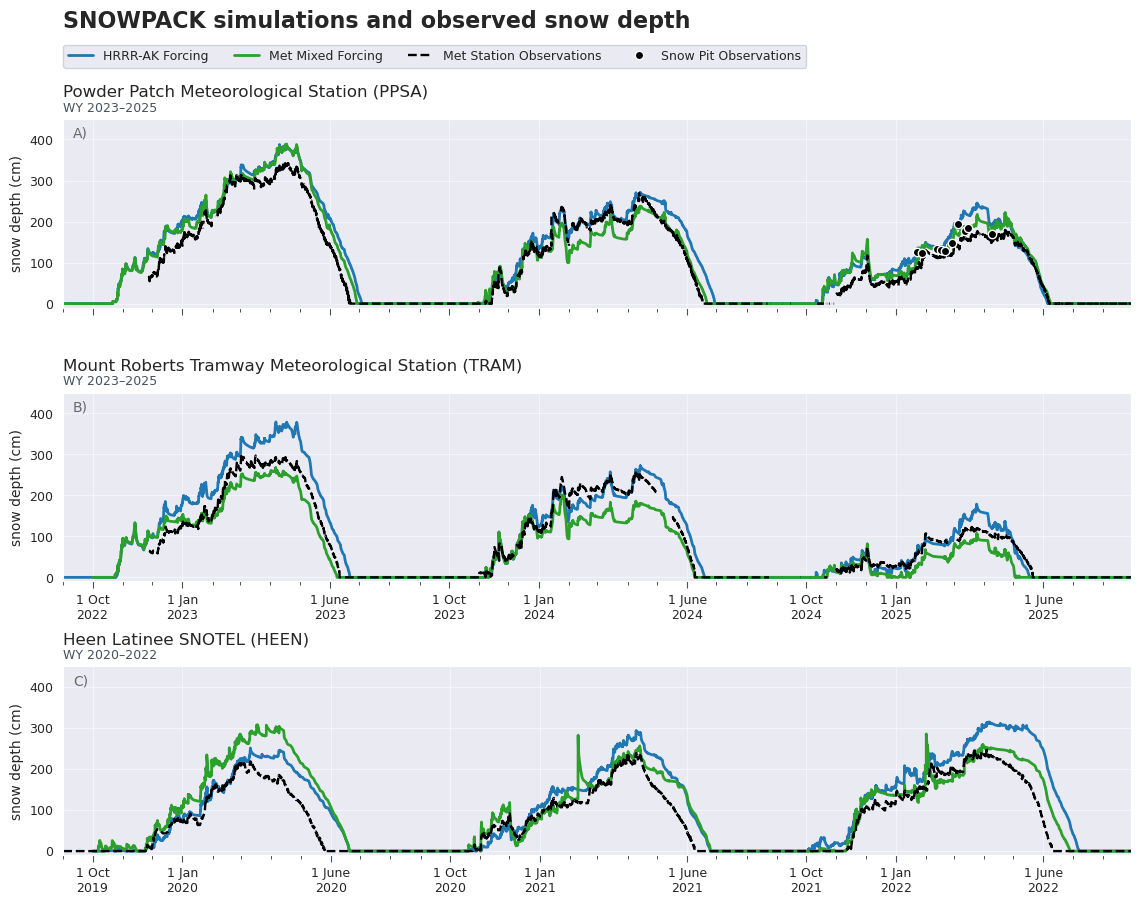

In [14]:
soil = load_simulations(main_forcings, 'soil')
fig = draw_figure(soil, 'figure4_publication', ymax=450)
plt.show()

## Supplementary figure | Base simulations

The supplement uses the original `_base` runs for all four forcing variants.
HEEN uses the archived historical outputs for this comparison.

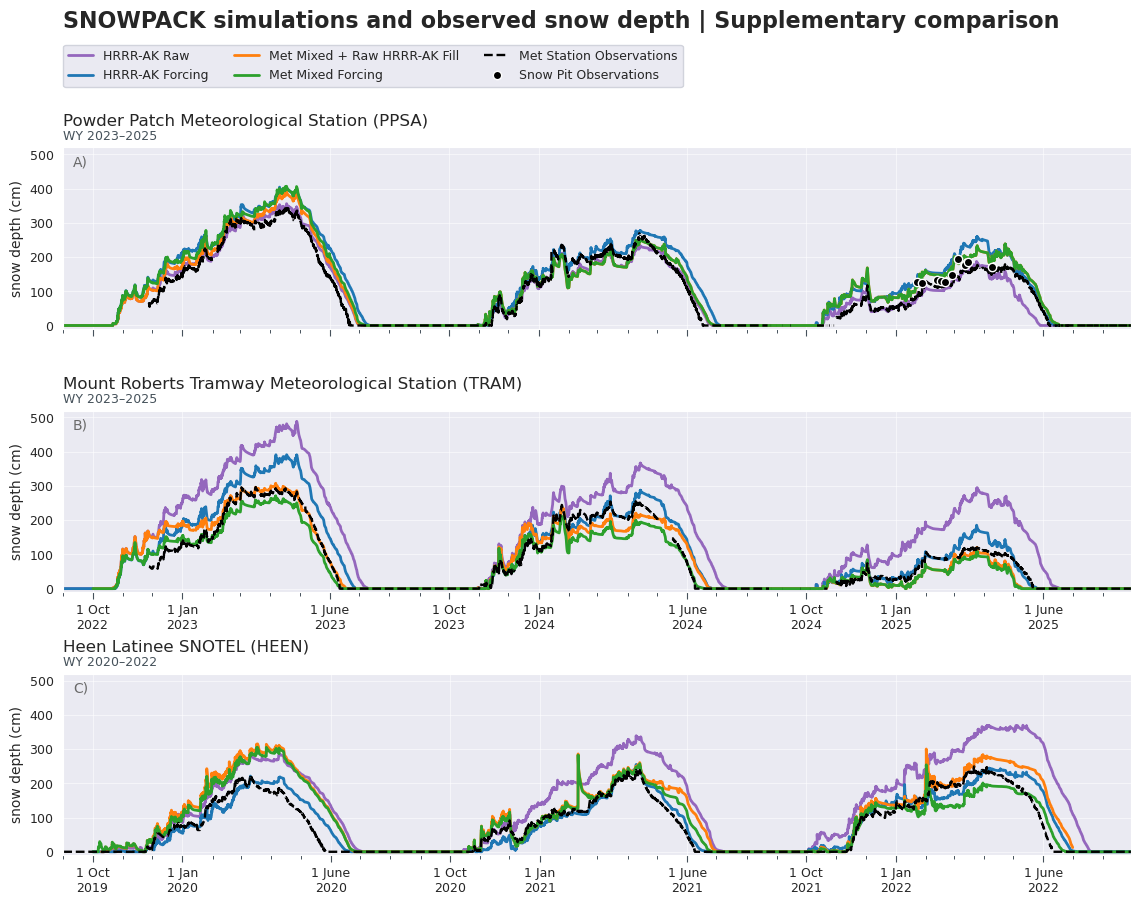

In [15]:
base = load_simulations(styles, 'base')
fig = draw_figure(base, 'figure4_publication_supplementary', ymax=520, supplementary=True)
plt.show()